# Aula 08 — Laboratório: Web Scraping com BeautifulSoup (Prática) · Conteúdo

**Unidade 2 — Aquisição e Preparação de Dados** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**🕸️ Aula 08 — Laboratório: Web Scraping com BeautifulSoup (Prática)**

Terceira aula da Unidade 2 (Aquisição e Preparação de Dados). Análise de HTML; seletores CSS; extração de tabelas; tratamento de paginação; uso ético e limitações legais. Prática com avaliações e resenhas de livros: a **Estante Potiguar** (mini-site de resenhas criado para a aula, que roda no seu computador) e o **Books to Scrape** (site real de treino de scraping). Recursos: Jupyter Notebook, `requests`, `BeautifulSoup4`. Avaliação: exercício prático entregue no Moodle + formulário avaliativo com 10 questões — prazo de envio até 24/10/2026. Materiais desta aula: livro Tópicos de Estudo (5 capítulos) · apostila completa em PDF · notebook do laboratório guiado · pacote com o site de resenhas, notebooks e dados · tarefa de entrega · formulário avaliativo.

---
## Tópicos de Estudo — Aula 08: Web Scraping com BeautifulSoup

### Descrição

Roteiro de leitura da Aula 08 em 5 capítulos curtos: o que é web scraping, anatomia do HTML e BeautifulSoup, seletores CSS, tabelas e paginação, uso ético e limitações legais.

### 1. Web scraping: o que é e quando usar

**Web scraping** é baixar páginas web com um programa e extrair delas, automaticamente, as informações de interesse. É a quarta família de fontes de dados vista na Aula 06 — e a mais frágil: a página foi feita para pessoas lerem, não para programas consumirem, e qualquer mudança no visual do site pode quebrar o código.

#### Ordem de preferência

1.  **Arquivo pronto** (CSV, Excel, portal de dados abertos);
2.  **API** (Aula 07) — canal oficial, estruturado e estável;
3.  **Web scraping** — quando o dado só existe na página HTML.

#### O fluxo de uma coleta

```text
requests.get(url) → resp.text (HTML) → BeautifulSoup → select(...) → lista de dicionários → DataFrame → CSV/JSON
```

#### Nossas fontes nesta aula

- **Estante Potiguar** — mini-site de resenhas de clássicos brasileiros, criado para a aula (leitores e comentários fictícios). Roda no seu computador com `python -m http.server 8000 --directory site_resenhas`.
- **Books to Scrape** (`books.toscrape.com`) — site real mantido para treino de scraping: 1.000 livros, preço e avaliação em estrelas, 50 páginas.

Grandes sites de resenhas reais (de livros ou restaurantes) costumam proibir a coleta automatizada nos Termos de Uso e publicam comentários de pessoas reais — por isso usamos fontes onde a coleta é permitida.

### 2. Anatomia do HTML e o BeautifulSoup

Uma página HTML é uma **árvore de tags**. Cada tag pode ter **atributos**; para scraping, os mais úteis são `class` e `id`. Uma resenha da Estante Potiguar:

```text
<article class="resenha" data-id="1">
  <h2 class="livro">Dom Casmurro</h2>
  <p class="autor">Machado de Assis</p>
  <div class="nota" data-nota="5">★★★★★</div>
  <p class="leitor">Por <span class="nome">Ana P.</span> em <time datetime="2026-09-02">02/09/2026</time></p>
  <p class="comentario">Releio a cada cinco anos...</p>
</article>
```

A mesma informação pode aparecer como texto (★★★★★, 02/09/2026) e como atributo (`data-nota="5"`, `datetime="2026-09-02"`). Prefira a versão mais limpa — normalmente o atributo.

#### BeautifulSoup em quatro linhas

In [ ]:
soup = BeautifulSoup(html, "html.parser")
soup.find("h2").get_text()                    # 'Dom Casmurro'
soup.find("div", class_="nota")["data-nota"]  # '5'
soup.find_all("article")                      # lista de tags

- `get_text(strip=True)` — texto visível, sem espaços nas pontas;
- `tag["atr"]` (erro se não existir) e `tag.get("atr")` (devolve `None`);
- `tag["class"]` devolve uma **lista**: `class="star-rating Three"` → `["star-rating", "Three"]`.

**Atenção à codificação:** se o servidor responde só `text/html`, sem charset, o `requests` assume ISO-8859-1 e "página" vira "pÃ¡gina", "£51.77" vira "Â£51.77". Corrija com `resp.encoding = "utf-8"` antes de usar `resp.text`.

**Dica:** use o botão direito → *Inspecionar* do navegador para descobrir tags, classes e atributos.

### 3. Seletores CSS na prática

Com `select()` e `select_one()` o BeautifulSoup aceita **seletores CSS**, a mesma linguagem usada nas folhas de estilo.

|                             |                                               |
|-----------------------------|-----------------------------------------------|
| Seletor                     | Encontra                                      |
| `.comentario`               | elementos com a classe comentario             |
| `#ranking`                  | o elemento com id ranking                     |
| `article.resenha`           | \<article\> com a classe resenha              |
| `article.resenha span.nome` | span.nome em qualquer nível dentro da resenha |
| `ul.paginacao > li`         | \<li\> filho direto da lista                  |
| `div[data-nota]`            | \ que tem o atributo data-nota          |

`select()` devolve uma **lista** (talvez vazia); `select_one()` devolve o primeiro elemento ou `None`.

#### Extraindo uma lista de resenhas

In [ ]:
for art in soup.select("article.resenha"):
    util = art.select_one(".util")          # pode não existir!
    registro = {
        "livro": art.select_one("h2.livro").get_text(strip=True),
        "nota": int(art.select_one("div.nota")["data-nota"]),
        "data": art.select_one("time")["datetime"],
        "util": int(util.get_text().split()[0]) if util else None,
    }

No Books to Scrape, a avaliação fica no nome da classe: `<p class="star-rating Three">` → `pod.select_one("p.star-rating")["class"][1]` devolve `"Three"`, que um dicionário converte em 3.

### 4. Tabelas e paginação

#### Tabelas HTML

Duas formas de transformar uma `<table>` em dados:

In [ ]:
# Manual (controle total)
tabela = soup.select_one("table#ranking")
linhas = [[td.get_text(strip=True) for td in tr.select("td")] for tr in tabela.select("tbody tr")]

# Pandas (rápido) — StringIO vem do módulo io
ranking = pd.read_html(StringIO(resp.text), attrs={"id": "ranking"}, decimal=",", thousands=".")[0]

`read_html` devolve uma lista de DataFrames. Com `decimal=","`, a nota "4,50" vira o número 4.5 — sem isso, a coluna fica como texto.

#### Paginação

A estratégia mais robusta é **seguir o link "próxima página" até ele não existir**. O `href` costuma ser relativo; `urljoin` monta o endereço completo.

In [ ]:
url = BASE      # endereço do site local (ver notebook)
while url:
    soup = BeautifulSoup(baixar(url).text, "html.parser")
    todas.extend(extrair_resenhas(soup))
    link = soup.select_one("li.proxima a")
    url = urljoin(url, link["href"]) if link else None
    time.sleep(PAUSA)   # PAUSA = 1 segundo

Resultado na Estante Potiguar: 3 páginas, 24 resenhas. No Books to Scrape, o link é `li.next a`; as 5 primeiras páginas trazem 100 livros (preço médio £34,56 em 09/10/2026).

### 5. Uso ético e limitações legais

Conseguir baixar uma página não significa poder coletá-la em massa. Antes de raspar:

- **Termos de Uso** — muitos sites proíbem a coleta automatizada.
- **robots.txt** — na raiz do site; lista caminhos proibidos (`Disallow`) e o intervalo entre requisições (`Crawl-delay`). Em Python: `urllib.robotparser.RobotFileParser`. A ausência do arquivo não é um "vale tudo".
- **Existe API?** Se existir, prefira-a.
- **Dados pessoais** — nomes, fotos e perfis são protegidos pela **LGPD** (Lei 13.709/2018) mesmo quando públicos. Colete só o necessário; anonimize quando possível.
- **Direitos autorais** — resenhas têm autoria: analisar estatisticamente é diferente de republicar.

#### Boas maneiras de um robô

- Identifique-se no `User-Agent`;
- espere entre requisições (`time.sleep`) e baixe só o necessário;
- guarde os dados localmente e registre a proveniência (fonte, URL, data).

#### Limitações técnicas

O `requests` só recebe o HTML enviado pelo servidor; páginas montadas por JavaScript aparecem vazias para o BeautifulSoup (seria preciso Selenium/Playwright). CAPTCHAs e bloqueios são sinais de que o site não quer ser raspado.

---
## Conteúdo — Aula 08: Web Scraping com BeautifulSoup (apostila em PDF)

> Convertido de [`Aula08_Web_Scraping_BeautifulSoup.pdf`](Aula08_Web_Scraping_BeautifulSoup.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 08 - Laboratório: Web Scraping com BeautifulSoup

Análise de HTML; seletores CSS; extração de tabelas; tratamento de paginação; uso ético e limitações legais

Unidade

Natureza Unidade 2 - Aquisição e Preparação de Dados (Aula 08, terceira aula)

Aula prática (laboratório)

Carga horária

4 h/a - 1h30 de exposição guiada + 2h30 de laboratório

Pré-

requisitos

Recursos Jupyter Notebook/Lab, requests , beautifulsoup4 , pandas , lxml

Avaliação

Professor Exercício prático entregue no Moodle + formulário avaliativo (10 questões) - prazo 24/10/2026

Plácido Antônio de Souza Neto

Aula 06 (fontes de dados) e Aula 07 ( requests , paginação, JSON/CSV)

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Reconhecer quando o web scraping é a fonte adequada (e quando uma API ou um arquivo pronto é preferível).
2. Analisar a estrutura de uma página HTML - tags, atributos, classes e ids - usando a ferramenta Inspecionar do navegador.
3. Extrair textos e atributos com o BeautifulSoup, usando find / find\_all e seletores CSS com select / select\_one .
4. Extrair tabelas HTML manualmente e com pandas.read\_html , tratando o padrão brasileiro de vírgula decimal.
5. Implementar paginação seguindo o link de "próxima página", com urljoin e intervalo entre requisições.
6. Aplicar boas práticas éticas e legais: robots.txt , termos de uso, identificação do robô, minimização de dados pessoais (LGPD).

### Sumário

### Parte I - Fundamentos teóricos

- 1.1 O que é web scraping (e quando usar)
- 1.2 O HTML é uma árvore
- 1.3 BeautifulSoup: do HTML ao objeto Python

- 1.4 Seletores CSS
- 1.5 Tabelas e paginação
- 1.6 Uso ético e limitações legais

Parte II - Laboratório guiado: resenhas e avaliações de livros

Parte III - Exercício prático (entrega no Moodle)

Parte IV - Formulário avaliativo

Apêndice A - Colinha do BeautifulSoup

Apêndice B - Referências e leituras recomendadas

### SOBRE OS DADOS USADOS NESTA AULA

A aula usa duas fontes de avaliações de livros . A primeira é a Estante Potiguar , um mini-site de resenhas de leitores criado para esta aula: os livros são clássicos brasileiros em domínio público, mas os leitores e comentários são fictícios . Ele vem no pacote da aula e roda no seu próprio computador - você pode errar e repetir à vontade, sem incomodar nenhum servidor real. A segunda é o Books to Scrape ( books.toscrape.com ), um site real mantido publicamente para quem quer treinar scraping: 1.000 livros com preço e avaliação em estrelas, em 50 páginas. Os resultados mostrados nesta apostila foram obtidos ao vivo em 09/10/2026 .

### POR QUE NÃO RASPAR UM SITE REAL DE RESENHAS?

Grandes sites de resenhas de livros e restaurantes (Goodreads, TripAdvisor, iFood etc.) proíbem a coleta automatizada em seus Termos de Uso, bloqueiam robôs e publicam comentários de pessoas reais - dados pessoais protegidos pela LGPD. Por isso a aula usa um site fictício para as resenhas e um site de treino para as avaliações. A técnica é exatamente a mesma; o que muda é que aqui a coleta é permitida.

### Parte I - Fundamentos teóricos

Do HTML ao DataFrame: o caminho completo de uma coleta por web scraping

### 1.1 O que é web scraping (e quando usar)

Web scraping é baixar páginas web com um programa e extrair delas, de forma automática, as informações de interesse. Na Aula 06 vimos que ele é a quarta família de fontes de dados - depois de arquivos, bancos de dados e APIs - e a mais frágil delas: a página foi feita para pessoas lerem, não para programas consumirem. Qualquer mudança no visual do site pode quebrar o seu código.

### A ordem de preferência

1. Arquivo pronto (CSV, Excel, dados abertos) - se existe, use.
2. API (Aula 07) - canal oficial, estruturado, estável.
3. Web scraping - quando o dado só existe na página HTML.

### O fluxo de uma coleta

```
requests.get(url)  →  resp.text (HTML)  →  BeautifulSoup  →  select(...)  →  lista de
```

```
dicionários  →  DataFrame  →  CSV/JSON
```

As duas primeiras etapas você já conhece da Aula 07. A novidade desta aula está no meio: transformar HTML em dados estruturados.

### 1.2 O HTML é uma árvore

Uma página HTML é um texto com tags aninhadas, formando uma árvore. Cada tag pode ter atributos ; os mais úteis para scraping são class e id , porque é por eles que o desenvolvedor do site organiza (e estiliza) o conteúdo. Uma resenha da Estante Potiguar, por exemplo, aparece assim no código-fonte da página e assim no navegador (Figura 1):

```
<article class="resenha" data-id="1"> <h2 class="livro">Dom Casmurro</h2> <p class="autor">Machado de Assis</p> <div class="nota" data-nota="5" title="5 de 5 estrelas">★★★★★</div> <p class="leitor">Por <span class="nome">Ana P.</span> em <time datetime="2026-0902">02/09/2026</time></p> <p class="comentario">Releio a cada cinco anos e sempre mudo de opinião sobre Capitu. ... </p> <span class="util">31 pessoas acharam útil</span> </article>
```

Figura 1 - A Estante Potiguar no navegador (site fictício da aula).

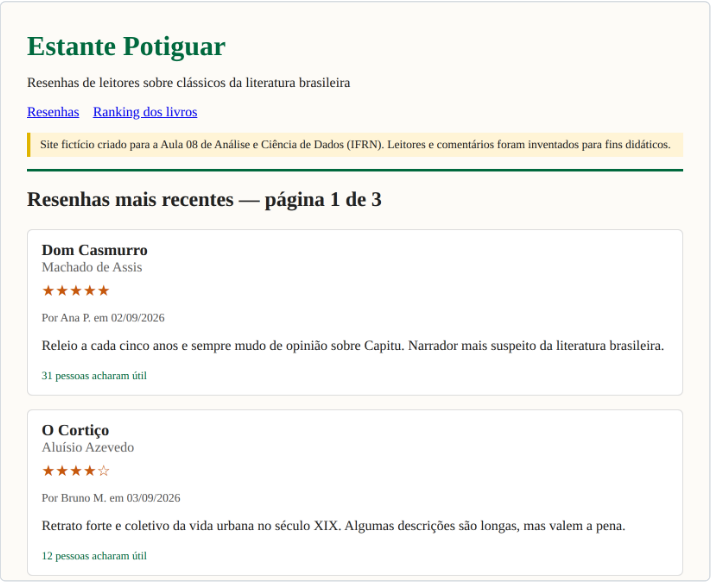

Repare que a mesma informação pode estar em lugares diferentes: a nota aparece como estrelas (texto visível) e como o atributo data-nota="5" ; a data aparece como "02/09/2026" (texto) e como datetime="2026-09-02" (atributo, já no formato ISO). Para análise, prefira sempre a versão mais limpa - normalmente o atributo.

### FERRAMENTA INDISPENSÁVEL: INSPECIONAR

No navegador, clique com o botão direito sobre o dado e escolha Inspecionar . O painel do desenvolvedor mostra exatamente a tag, as classes e os atributos daquele trecho - é dali que saem os seletores que você vai usar no código.

### 1.3 BeautifulSoup: do HTML ao objeto Python

A biblioteca beautifulsoup4 ( pip install beautifulsoup4 ) lê o texto HTML e devolve um objeto que se navega com Python. O analisador "html.parser" já vem com o Python; o "lxml" é mais rápido e tolerante a HTML malformado.

In [ ]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(html, "html.parser")

soup.find("h2").get_text()                    # primeira tag <h2>  → 'Dom Casmurro'
soup.find("p", class_="autor").get_text()     # <p class="autor">   → 'Machado de Assis'
soup.find("div", class_="nota")["data-nota"]  # valor de atributo   → '5'
soup.find_all("article")                      # lista com todas as tags <article>

### Lendo texto e atributos

- tag.get\_text(strip=True) - o texto visível, sem espaços nas pontas;
- tag["atributo"] - o valor do atributo (erro se não existir); tag.get("atributo") devolve None em vez de erro;
- tag["class"] - devolve uma lista , porque uma tag pode ter várias classes ( class="starrating Three" → ["star-rating", "Three"] ).

### ATENÇÃO À CODIFICAÇÃO (ACENTOS E SÍMBOLOS)

Se o servidor responder apenas Content-Type: text/html , sem informar o charset , o requests assume ISO-8859-1. Se a página estiver em UTF-8 (o mais comum), os acentos se embaralham: "página" vira "pÃ¡gina" e "£51.77" vira "Â£51.77". Isso acontece tanto com o servidor local da Estante Potiguar quanto com o Books to Scrape. A correção: resp.encoding = "utf-8" antes de usar resp.text .

### 1.4 Seletores CSS

Além de find / find\_all , o BeautifulSoup aceita seletores CSS - a linguagem que os sites usam para aplicar estilos. São mais curtos e servem igualmente no navegador, no Selenium e no Scrapy.

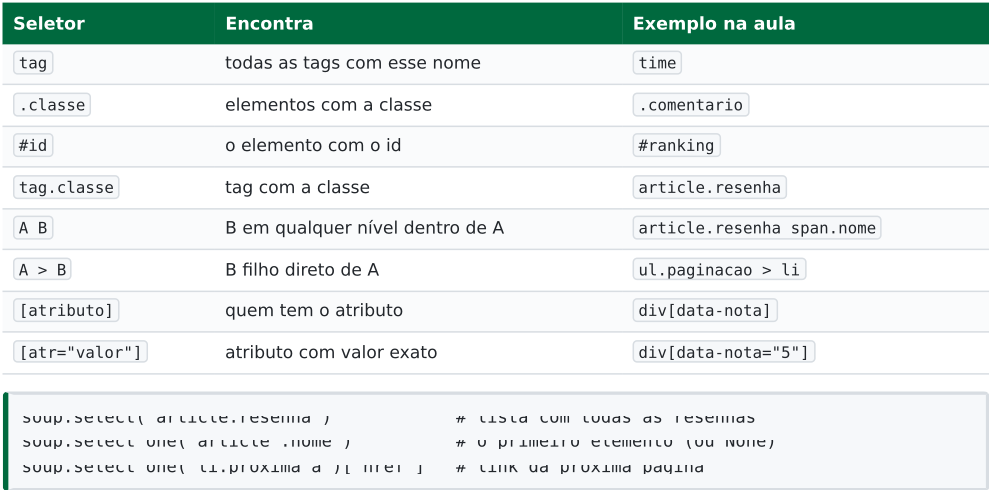

select() devolve sempre uma lista (possivelmente vazia); select\_one() devolve o primeiro elemento ou None . Esse None é importante: em dados reais, nem todo item tem todos os campos. Na Estante Potiguar, duas resenhas não têm o contador "pessoas acharam útil" - e art.select\_one(".util").get\_text() quebraria com AttributeError . O padrão seguro é:

In [ ]:
util = art.select_one(".util")
valor = int(util.get_text().split()[0]) if util else None

### 1.5 Tabelas e paginação

### Tabelas HTML

Tabelas ( &lt;table&gt; , &lt;tr&gt; , &lt;th&gt; , &lt;td&gt; ) são o formato mais amigável para scraping. Há dois caminhos:

```
# 1) Manual, com BeautifulSoup — controle total
tabela = soup.select_one("table#ranking")
cabecalho = [th.get_text(strip=True) for th in tabela.select("thead th")]
linhas = [[td.get_text(strip=True) for td in tr.select("td")] for tr in tabela.select("tbody
tr")]

# 2) Pandas — rápido quando a tabela é bem formada
from io import StringIO
ranking = pd.read_html(StringIO(resp.text), attrs={"id": "ranking"}, decimal=",",
thousands=".")[0]
```

pd.read\_html devolve uma lista de DataFrames (um por tabela encontrada); attrs filtra pela tabela desejada. Como a nota média está no padrão brasileiro ( 4,50 ), o parâmetro decimal="," é o que garante que a coluna vire número.

### Paginação

Listas longas são divididas em páginas. A estratégia mais robusta é seguir o link de "próxima página" até ele não existir mais - o código não precisa saber quantas páginas há. Como o href costuma ser relativo ( pagina-2.html , ../../../livro/index.html ), urljoin monta o endereço completo:

In [ ]:
url = "http://localhost:8000/"
while url:
    soup = BeautifulSoup(baixar(url).text, "html.parser")
    todas.extend(extrair_resenhas(soup))
    link = soup.select_one("li.proxima a")
    url = urljoin(url, link["href"]) if link else None
    time.sleep(1)                      # respeite o Crawl-delay

### 1.6 Uso ético e limitações legais

Poder baixar uma página não significa poder coletá-la em massa. Antes de raspar, responda:

- Os Termos de Uso permitem? Muitos sites proíbem expressamente a coleta automatizada. Violar os termos pode levar a bloqueio e a disputas judiciais.
- O que diz o robots.txt ? Fica na raiz do site ( /robots.txt ) e lista caminhos proibidos ( Disallow ) e, às vezes, o intervalo mínimo entre requisições ( Crawl-delay ). Em Python: urllib.robotparser.RobotFileParser . A ausência do arquivo (como no Books to Scrape, que responde 404) não é um "vale tudo".
- Existe uma API? Se existir, use-a.
- Há dados pessoais? Nomes, fotos e perfis de pessoas são dados pessoais protegidos pela LGPD (Lei 13.709/2018) mesmo quando estão públicos. Colete só o necessário e

anonimize quando possível.

- Direitos autorais: comentários e resenhas são textos com autoria; analisar estatisticamente é diferente de republicar o conteúdo.

### Boas maneiras de um robô

- Identifique-se: headers={"User-Agent": "AulaACD-IFRN/1.0 (atividade educacional)"} ;
- Espere entre requisições ( time.sleep ) e baixe só o necessário;
- Guarde o HTML/dados localmente para não repetir a coleta;
- Registre a proveniência (fonte, URL, data) junto com os dados, como na Aula 07.

### LIMITAÇÕES TÉCNICAS

O requests baixa apenas o HTML enviado pelo servidor. Sites que montam o conteúdo com JavaScript depois que a página carrega (muitas lojas e redes sociais) aparecem "vazios" para o BeautifulSoup; nesses casos seria preciso um navegador automatizado (Selenium, Playwright) - assunto fora do escopo desta aula. CAPTCHAs e bloqueios por excesso de requisições são sinais claros de que o site não quer ser raspado.

### Parte II - Laboratório guiado: resenhas e avaliações de livros

Os mesmos passos estão no notebook Aula08\_Web\_Scraping\_BeautifulSoup.ipynb, com todas as saídas

### Passo 1 - Colocar a Estante Potiguar no ar e ler o robots.txt

In [ ]:
servidor = subprocess.Popen([sys.executable, "-m", "http.server", "8000", "--directory",
"site_resenhas"])
robo = RobotFileParser("http://localhost:8000/robots.txt"); robo.read()

```
index.html                permitido? True
ranking.html              permitido? True
privado/rascunhos.html    permitido? False
Intervalo pedido entre requisições (Crawl-delay): 1 s
```

### Passo 2 - Baixar a página e corrigir a codificação

```
Content-Type: text/html
Encoding adivinhado pelo requests: ISO-8859-1
Título lido sem corrigir: Resenhas â pÃ¡gina 1 | Estante Potiguar
Título corrigido: Resenhas — página 1 | Estante Potiguar
Resenhas nesta página: 8
```

### Passo 3 - Extrair cada resenha em um dicionário

In [ ]:
def extrair_resenhas(soup):
    registros = []
    for art in soup.select("article.resenha"):
        util = art.select_one(".util")
        registros.append({
            "livro": art.select_one("h2.livro").get_text(strip=True),
            "autor": art.select_one("p.autor").get_text(strip=True),
            "nota": int(art.select_one("div.nota")["data-nota"]),
            "leitor": art.select_one("span.nome").get_text(strip=True),
            "data": art.select_one("time")["datetime"],
            "comentario": art.select_one("p.comentario").get_text(strip=True),
            "util": int(util.get_text().split()[0]) if util else None,
        })
    return registros

### Passo 4 - Paginação seguindo "Próxima"

```
http://localhost:8000/                   -> 8 resenhas (acumulado: 8)
http://localhost:8000/pagina-2.html      -> 8 resenhas (acumulado: 16)
http://localhost:8000/pagina-3.html      -> 8 resenhas (acumulado: 24)

                                  resenhas  media
O Alienista                              4   4.50
Dom Casmurro                             4   4.25
Memórias Póstumas de Brás Cubas          4   4.25
O Cortiço                                4   4.00
Triste Fim de Policarpo Quaresma         4   4.00
Iracema                                  4   3.50

Resenhas sem o contador 'útil': 2
```

### Passo 5 - A tabela de ranking com pd.read\_html

```
   Posição                             Livro             Autor   Ano  Resenhas  Nota média
0        1                       O Alienista  Machado de Assis  1882         4        4.50
1        2                      Dom Casmurro  Machado de Assis  1899         4        4.25
2        3   Memórias Póstumas de Brás Cubas  Machado de Assis  1881         4        4.25
...
Nota média    float64      ← a vírgula decimal foi convertida graças a decimal=","
```

### Passo 6 - Site real: Books to Scrape

Cada livro do catálogo é um &lt;article class="product\_pod"&gt; . O título completo está no atributo title do link (o texto visível vem cortado) e a avaliação está escondida no nome da classe : &lt;p class="star-rating Three"&gt; .

In [ ]:
NOTAS = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
for pod in soup.select("article.product_pod"):
    titulo = pod.select_one("h3 a")["title"]
    preco  = float(pod.select_one("p.price_color").get_text().replace("£", ""))
    nota   = NOTAS[pod.select_one("p.star-rating")["class"][1]]

```
Page 1 of 50 -> 20 livros   ...   Page 5 of 50 -> 100 livros
Preço médio: £ 34.56

nota   count   mean (preço)
1         22   35.52
2         19   35.91
3         22   36.84
4         18   33.98
5         19   30.01
```

E a tabela de informações da página de um livro ( table.table-striped , pares &lt;th&gt; / &lt;td&gt; ):

```
Título: A Light in the Attic   |   Categoria: Poetry
  UPC                  a897fe39b1053632
  Price (excl. tax)    £51.77
  Availability         In stock (22 available)
  Number of reviews    0
```

Curiosidade: na amostra, os livros com 5 estrelas têm o menor preço médio. Como o site é de treino, preço e nota são gerados sem relação entre si - numa análise real, um achado assim seria ponto de partida para investigação, nunca uma conclusão.

### Parte III - Exercício prático

Entrega no Moodle - prazo 24/10/2026

### Exercício Prático - Aula 08: raspando avaliações de livros

Use o notebook Aula08\_Exercicio\_Pratico.ipynb (no pacote da aula) como ponto de partida: ele já traz a estrutura e os trechos marcados com TODO . Coloque-o na mesma pasta da subpasta site\_resenhas/ .

### Parte A - Estante Potiguar (site fictício, roda no seu computador)

1. Coloque o site no ar com python -m http.server 8000 --directory site\_resenhas (a célula do notebook já faz isso) e raspe todas as resenhas , seguindo o link "Próxima" ( li.proxima a ) e esperando 1 s entre as páginas.
2. Monte um DataFrame com livro , autor , nota (atributo data-nota ), leitor , data (atributo datetime ), comentario e util (use None quando o contador não existir).
3. Calcule, por autor, o número de resenhas e a nota média.
4. Mostre a resenha mais útil (maior util ).
5. Leia a tabela table#ranking de ranking.html com pd.read\_html(..., decimal=",") e confira se as médias batem com as suas.

Para conferir: são 24 resenhas em 3 páginas; Machado de Assis tem 12 resenhas e nota média 4,33; a resenha mais útil é de Ana P . sobre Dom Casmurro (31 pessoas); 2 resenhas não têm o contador "útil".

### Parte B - Books to Scrape (site real de treino, books.toscrape.com )

6. Escolha uma categoria com pelo menos 2 páginas . Opções (nº de livros / páginas): Mystery (32/2), Historical Fiction (26/2), Romance (35/2), Childrens (29/2), Food and Drink (30/2), Fantasy (48/3), Young Adult (54/3), Sequential Art (75/4), Fiction (65/4), Nonfiction (110/6). Os links ficam em div.side\_categories ul li ul li a na página inicial.
7. Raspe todos os livros da categoria seguindo li.next a até o fim, esperando 1 segundo entre as páginas ( time.sleep ). Para cada livro: titulo (atributo title do link), preco (float, sem o £), nota de 1 a 5 (a partir da classe star-rating ) e link absoluto (use urljoin : nas categorias o href começa com ../../../ ).
8. Calcule o total de livros, o preço médio, a distribuição das notas e os 3 livros mais bem avaliados (desempate pelo menor preço).
9. Abra a página de detalhe de um desses livros e extraia a tabela table.table-striped em um dicionário.

Exemplo de resultado (categoria Mystery, coletada em 09/10/2026): 32 livros em 2 páginas; preço médio £31,72; notas 1 ★ : 7, 2 ★ : 5, 3 ★ : 8, 4 ★ : 7, 5 ★ : 5; três mais bem avaliados: The Girl You Lost (£12,29), The Silkworm (Cormoran Strike #2) (£23,05) e What Happened on Beale Street (£25,37) - todos com 5 estrelas. Lembre de definir resp.encoding = "utf-8" , senão o preço vem como Â£ .

### Parte C - Salvar e refletir

10. Salve as resenhas (CSV) e os livros da categoria (CSV + JSON com proveniência: fonte, URL, data da coleta).
11. Em uma célula Markdown (3 a 5 linhas), explique os cuidados éticos e legais que você tomou (robots.txt, identificação no User-Agent, intervalo entre requisições, dados pessoais/LGPD) e o que mudaria se o site não permitisse a coleta.
3. O que entregar: o notebook executado (com as saídas visíveis) + os arquivos CSV/JSON, compactados em um único .zip .

Prazo: até 24/10/2026 (23h59) - 15 dias após esta aula.


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha do BeautifulSoup

| Tarefa | Código |
|--------------------------|-------------------------------------------------------------------|
| Baixar com identificação | requests.get(url, headers={"User-Agent": "..."}, timeout=10) |
| Corrigir codificação | resp.encoding = "utf-8" |
| Criar o objeto | soup = BeautifulSoup(resp.text, "html.parser") |
| Primeiro elemento | soup.find("p", class_="autor") · soup.select_one("p.autor") |
| Todos os elementos | soup.find_all("article") · soup.select("article.resenha") |
| Texto | tag.get_text(strip=True) |
| Atributo | tag["href"] · tag.get("href") · tag["class"] (lista) |
| URL absoluta | urljoin(url_atual, tag["href"]) |
| Tabela → DataFrame | pd.read_html(StringIO(html), attrs={"id": "..."}, decimal=",")[0] |
| robots.txt | rp = RobotFileParser(url); rp.read(); rp.can_fetch(ua, url) |
| Pausa | time.sleep(1) |

### Apêndice B - Referências e leituras recomendadas

- RICHARDSON, Leonard. Beautiful Soup Documentation . www.crummy.com/software/BeautifulSoup/bs4/doc
- REQUESTS. Requests: HTTP for Humans . requests.readthedocs.io
- PANDAS. pandas.read\_html . pandas.pydata.org/docs/reference/api/pandas.read\_html.html
- MDN WEB DOCS. CSS selectors . developer.mozilla.org/enUS/docs/Web/CSS/CSS\_selectors
- PYTHON. urllib.robotparser - Parser for robots.txt . docs.python.org/3/library/urllib.robotparser.html
- BRASIL. Lei nº 13.709/2018 - Lei Geral de Proteção de Dados Pessoais (LGPD) . planalto.gov.br
- TOSCRAPE. Books to Scrape - a sandbox for web scraping . books.toscrape.com

### O que vem na próxima aula

Qualidade de Dados e Limpeza - os dados coletados nas Aulas 07 e 08 raramente chegam prontos: valores ausentes (como o contador "útil"), formatos inconsistentes e duplicatas são o tema da Aula 09.

Aula 08 - Laboratório: Web Scraping com BeautifulSoup · Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN